In [3]:
### my stuff ###
import sys
sys.path.append('..')
from consts import *
from functions import *

sys.path.append('../thermionicRates/')
from argon import mB_velocity, mB_SI_velocity

### python stuff ###
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as tk
from scipy.optimize import curve_fit
import scipy.misc as misc
import scipy.special as sp
from scipy import integrate
from scipy.interpolate import interp1d

### Calculating effect of CM scattering angle on recoil spectra

We calculate the lab recoil energy for various weight targets, and various Mass incoming DM at ~270km/s.
* scattering is elastic
* transform from lab frame to CM frame
* transform back to lab frame for various CM scatter angles
* v1 will neglect DM velocity distribution, and thermal motion
___
### Variables
Vector indications are ignored for ease of writing. When discussing speeds the absolute value signs will be used, so $v$ is a vector, $|v|$ is a scalar
<p style="text-align: center;">
$u$ - velocity before collision (lab) <br>
$v$ - velocity after collision (lab)  <br>
$u'$ - (primed) velocity in CM frame  <br>
$V$ - CM frame velocity (In lab)  <br>
$\theta$ - CM frame scattering angle <br>
$u_1$ - incoming particle, mass $m_1$  <br>
$u_2$ - target, mass $m_2$  <br>
$M$ - total mass $m_1 + m_2$ <br>
<b> $K$ - recoil kinetic energy of M in lab </b>
</p>

$$ K = \frac{1}{2} mv_2^2 $$

The center of mass $\mathbf{R}$ is defined as:
$$(m_1 + m_2)R = mr_2 + Mr_2$$

Taking the derivative gives the velocity of the CM frame $\mathbf{V}$
\begin{equation}
    V = \frac{dR}{dT} = \frac{1}{M}(m_1u_2 + m_2u_2)
\end{equation}

#### <b>Important Physics Step</b>
In the CM frame, total momentum is zero. This is important because after the scatter, the vectors $v_1'$ and $v_2'$ must be aligned so net momentum along $\vec{x}$ and $\vec{y}$ remains zero. This means both particles scatter at the same angle (denoted as $\theta$) in the CM frame. For elastic collisions, by conservation of energy combined with the equal scattering angles, <b>the incoming and outgoing CM speeds are also equal:</b>
<p style="text-align: center;"> $|u_1'| = |v_1'|$ and $|u_2'| = |v_2'|$ </p>

### <b> CM frame to Lab Frame </b>
This calculation originally began by posing the question:
<center> <b> What is $$\frac{d \sigma}{d\theta}$$ for elastic DM scattering?</b></center>
If all the scatters are hard, then there will be more high energy events, and vice versa. Detectors measure the recoil energy in the lab frame so this differential cross-section matters (or does it?)  
</br>
</br>
The scatter in the CM frame will yield the resulting scattered vector $v'_2$

$$ v'_2 = \mathbf{\hat{x}}|u'_2| \cos \theta  + \mathbf{\hat{y}} |u'_2| \sin \theta  $$

The conversion from one frame to another is as below (the same for $u$ or $v$):
$$ u_1' = u_1 - V \quad \quad u_2' = u_2 - V $$
If the target is at rest then $u_2 = 0$ and

$$ u_2' = -V \quad \quad |u_2'| = |v_2'| = |V| = V_x$$

and converting back to the lab frame (remember these are vectors):
$$ v_2 = v'_2 + V $$ 
$$ v'_2 = |u'_2| \big( \mathbf{\hat{x}} \cos{\theta} + \mathbf{\hat{y}} \sin{\theta} \big)$$

$$ v_2 = \mathbf{\hat{x}} \big( u'_2 \cos\theta + V_x \big) + \mathbf{\hat{y}} \big(|u'_2| \sin \theta + V_y \big) $$

With the target initially at rest $|V| = V_x$, this simplifies

$$ v_2 = \mathbf{\hat{x}} \big( |u'_2| \cos\theta + V_x \big) + \mathbf{\hat{y}} |u'_2| \big( \sin \theta \big)$$
$$ v_2 = \mathbf{\hat{x}} |V|\big( 1 - \cos\theta \big) + \mathbf{\hat{y}} |V| \big( \sin \theta \big)$$
$$ v_2 = |V| \big( \mathbf{\hat{x}} (1 - \cos\theta) + \mathbf{\hat{y}} \sin\theta \big) $$

so the magnitude of $|v_2|^2$ is
$$ |v_2|^2 = |V|^2 \big[ 1 -2\cos\theta +\cos^2\theta + \sin^2\theta \big]) $$
$$ |v_2|^2 = 2|V|^2 (1 - \cos\theta) $$

so the recoil kinetic energy $K$ in the lab frame, with CM scatter angle $\theta$ is:
$$ K = m_2 |V|^2 (1 - \cos\theta)$$

As a logic aside
* $V$ > 0, to the right
* $u_1 > u_1'$
* $u_2 = 0$
* $u'_2$ < 0,  to the left

writing out after complete algebra:

$$ v_2^2 = 2 \big( \frac{m_1u_1}{m1+m2} \big)^2(1-\cos\theta) $$  

$$ K = m_2\big( \frac{m_1u_1}{m1+m2} \big)^2(1-\cos\theta) $$

or with $m$ = mass DM, $M$ = mass target, $u$ = dark matter velocity

$$ K = m_2\big( \frac{m_1u_1}{m1+m2} \big)^2(1 - \cos\theta) $$

In [5]:
# all for u2 = 0 (so u'2 = - V)

# positive is to the right!

# scalar for now
def getCMV_scal(m1, u1, m2, u2):
    # mass in same units, u in m/s
    return (m1*u1 + m2*u2)/(m1 + m2)

def getCM_u2(m1, u1, m2, u2):
    V = getCMV_scal(m1, u1, m2, u2)
    return -V

# raw copy of equation written above
# m1, m2 in amu
# u1, u2 in m/s (both positive)
# output in eV
def get_recoilK(m1, u1, m2, u2, theta):
    
    V = getCMV_scal(m1, u1, m2, u2)
    vv = V/c
    K = m2 * amu * (vv**2) * (1 - np.cos(theta*np.pi/180))
    return K

def get_recoilK_v2(m1, u1, m2, theta):
    # this is from complete math, with simplification u2 = 0
    
    K_badUnits = m2*m1**2 * u1**2 /((m1 + m2)**2)*(1 - np.cos(theta*np.pi/180))
    return K_badUnits*amu/c/c

In [6]:
# get_recoilK(0.7, 300e3, 40, 0, 180)

# get_recoilK_v2(0.7, 300e3, 40, 180)

In [7]:
dmMasses = np.logspace(start = np.log10(0.5), stop = 2, num = 100, base = 10) # amu

angles = np.arange(5, 180, 5)


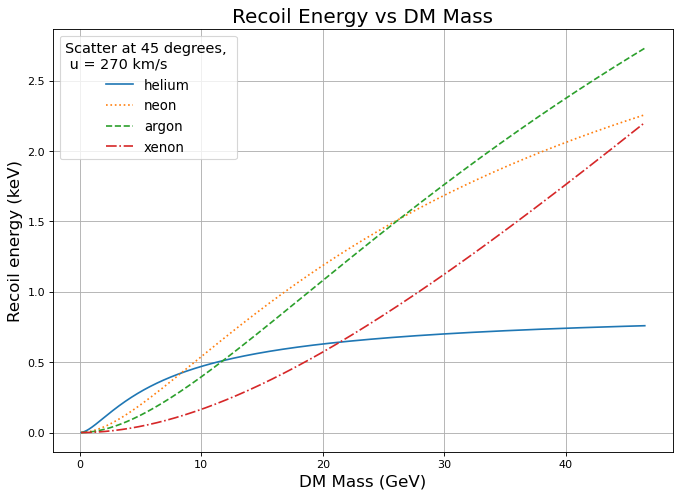

In [166]:
# comparing mass ratios
compDMmasses = np.arange(0.1, 50, 0.05)
compTmass = 40
ahard = 45
plt.figure(figsize=(10, 7), dpi=80)

plt.plot(compDMmasses * amu/1e9, (1/1000) * get_recoilK_v2(m1=compDMmasses, u1 = 270e3, m2 = 4, theta = ahard), label = "helium")
plt.plot(compDMmasses * amu/1e9, (1/1000) * get_recoilK_v2(m1=compDMmasses, u1 = 270e3, m2 = 20, theta = ahard), label = "neon", linestyle = "dotted")
plt.plot(compDMmasses * amu/1e9, (1/1000) * get_recoilK_v2(m1=compDMmasses, u1 = 270e3, m2 = 40, theta = ahard), label = "argon", linestyle = "--")
# plt.plot(compDMmasses * amu/1e9, (1/1000) * get_recoilK_v2(m1=compDMmasses, u1 = 300e3, m2 = 40, theta = 90), label = "argon, 90 degrees", linestyle = "--")
plt.plot(compDMmasses * amu/1e9, (1/1000) * get_recoilK_v2(m1=compDMmasses, u1 = 270e3, m2 = 132, theta = ahard), label = "xenon", linestyle = "dashdot")

plt.title("Recoil Energy vs DM Mass", fontsize = 18)
plt.ylabel("Recoil energy (keV)", fontsize = 15)
plt.xlabel("DM Mass (GeV)", fontsize = 15)
# plt.xlim(0, 5)
plt.legend(title="Scatter at 45 degrees, \n u = 270 km/s", title_fontsize = 13, fontsize = 12)

plt.savefig("recoil_DMmass.png", bbox_inches='tight')
plt.grid()
plt.show()

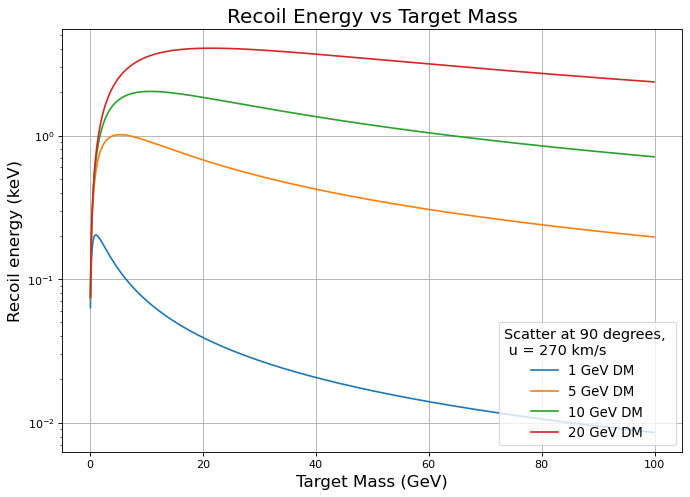

In [165]:
# comparing target masses
compTmasses = np.arange(0.1, 100, 0.1)
ahard = 90

plt.figure(figsize=(10, 7), dpi=80)
# plt.plot(compTmasses, (1/1000) * get_recoilK_v2(m1=0.1/amu*1e9, u1 = 300e3, m2 = compTmasses, theta = ahard), label = "0.1 GeV DM")
plt.semilogy(compTmasses, (1/1000) * get_recoilK_v2(m1=1/amu*1e9, u1 = 270e3, m2 = compTmasses, theta = ahard), label = "1 GeV DM")
plt.semilogy(compTmasses, (1/1000) * get_recoilK_v2(m1=5/amu*1e9, u1 = 270e3, m2 = compTmasses, theta = ahard), label = "5 GeV DM")
plt.semilogy(compTmasses, (1/1000) * get_recoilK_v2(m1=10/amu*1e9, u1 = 270e3, m2 = compTmasses, theta = ahard), label = "10 GeV DM")
plt.semilogy(compTmasses, (1/1000) * get_recoilK_v2(m1=20/amu*1e9, u1 = 270e3, m2 = compTmasses, theta = ahard), label = "20 GeV DM")

plt.title("Recoil Energy vs Target Mass", fontsize = 18)
plt.ylabel("Recoil energy (keV)", fontsize = 15)
plt.xlabel("Target Mass (GeV)", fontsize = 15)
plt.legend(title="Scatter at 90 degrees, \n u = 270 km/s", title_fontsize = 13, fontsize = 12, loc = "lower right")

plt.savefig("Recoil_target.png", bbox_inches='tight')
plt.grid()
plt.show()

In [126]:
a = [1.] * 10
a

[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

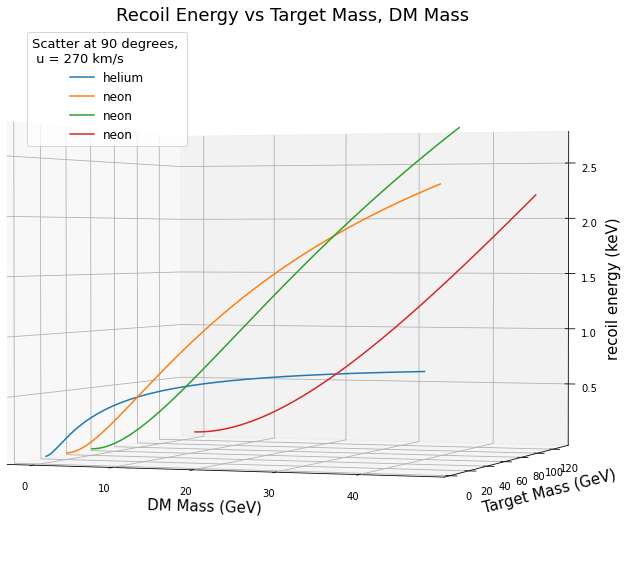

In [156]:
### testing
fig = plt.figure(figsize = (10,10))
ax = plt.axes(projection='3d')

compDMmasses = np.arange(0.1, 50, 0.05)
ahard = 45

mhe = 4
mne = 20
mar = 40
mxe = 131

# x - DM mass
# y - target mass
# z - recoil energy

ax.plot3D(compDMmasses * amu/1e9, np.array([mhe]*len(compDMmasses)), (1/1000) * get_recoilK_v2(m1=compDMmasses, u1 = 270e3, m2 = mhe, theta = ahard), label = "helium")
ax.plot3D(compDMmasses * amu/1e9, np.array([mne]*len(compDMmasses)), (1/1000) * get_recoilK_v2(m1=compDMmasses, u1 = 270e3, m2 = mne, theta = ahard), label = "neon")
ax.plot3D(compDMmasses * amu/1e9, np.array([mar]*len(compDMmasses)), (1/1000) * get_recoilK_v2(m1=compDMmasses, u1 = 270e3, m2 = mar, theta = ahard), label = "neon")
ax.plot3D(compDMmasses * amu/1e9, np.array([mxe]*len(compDMmasses)), (1/1000) * get_recoilK_v2(m1=compDMmasses, u1 = 270e3, m2 = mxe, theta = ahard), label = "neon")

# Data for a three-dimensional line
# zline = np.linspace(0, 15, 1000)
# xline = np.sin(zline)
# yline = np.cos(zline)
# ax.plot3D(xline, yline, zline, 'gray')

ax.set_title("Recoil Energy vs Target Mass, DM Mass", fontsize = 18)
ax.set_xlabel("DM Mass (GeV)", fontsize = 15)
ax.set_zlabel("recoil energy (keV)", fontsize = 15)
ax.set_ylabel("Target Mass (GeV)", fontsize = 15)
ax.legend(title="Scatter at 90 degrees, \n u = 270 km/s", title_fontsize = 13, fontsize = 12, loc = "upper left")

ax.azim = -70
ax.dist = 8
ax.elev = 1

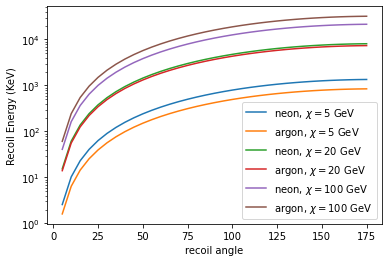

In [46]:
plt.semilogy(angles, get_recoilK(m1 = 5e9/amu, u1 = 270e3, m2 = 20, u2 = 0, theta = angles), label = r"neon, $\chi = 5$ GeV")
plt.semilogy(angles, get_recoilK(m1 = 5e9/amu, u1 = 270e3, m2 = 40, u2 = 0, theta = angles), label = r"argon, $\chi = 5$ GeV")

plt.semilogy(angles, get_recoilK(m1 = 20e9/amu, u1 = 270e3, m2 = 20, u2 = 0, theta = angles), label = r"neon, $\chi = 20$ GeV")
plt.semilogy(angles, get_recoilK(m1 = 20e9/amu, u1 = 270e3, m2 = 40, u2 = 0, theta = angles), label = r"argon, $\chi = 20$ GeV")

plt.semilogy(angles, get_recoilK(m1 = 100e9/amu, u1 = 270e3, m2 = 20, u2 = 0, theta = angles), label = r"neon, $\chi = 100$ GeV")
plt.semilogy(angles, get_recoilK(m1 = 100e9/amu, u1 = 270e3, m2 = 40, u2 = 0, theta = angles), label = r"argon, $\chi = 100$ GeV")

# plt.semilogy(angles, get_recoilK(m1 = 1000e9/amu, u1 = 270e3, m2 = 40, u2 = 0, theta = angles), label = r"Argon, $\chi = 100$ GeV")
# plt.semilogy(angles, get_recoilK(m1 = 1000e9/amu, u1 = 270e3, m2 = 130, u2 = 0, theta = angles), label = r"Xenon, $\chi = 100$ GeV")

plt.ylabel("Recoil Energy (KeV)")
plt.xlabel("recoil angle")
plt.legend()
plt.show()

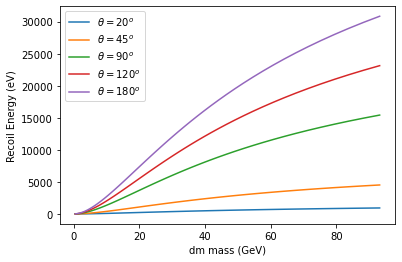

In [11]:

plt.plot(dmMasses* amu/1e9, get_recoilK(m1 = dmMasses, u1 = 270e3, m2 = 40, u2 = 0, theta = 20), label = r"$\theta = 20^o$")

plt.plot(dmMasses* amu/1e9, get_recoilK(m1 = dmMasses, u1 = 270e3, m2 = 40, u2 = 0, theta = 45), label = r"$\theta = 45^o$")

plt.plot(dmMasses* amu/1e9, get_recoilK(m1 = dmMasses, u1 = 270e3, m2 = 40, u2 = 0, theta = 90), label = r"$\theta = 90^o$")

plt.plot(dmMasses* amu/1e9, get_recoilK(m1 = dmMasses, u1 = 270e3, m2 = 40, u2 = 0, theta = 120), label = r"$\theta = 120^o$")

plt.plot(dmMasses* amu/1e9, get_recoilK(m1 = dmMasses, u1 = 270e3, m2 = 40, u2 = 0, theta = 180), label = r"$\theta = 180^o$")

plt.ylabel("Recoil Energy (eV)")
plt.xlabel("dm mass (GeV)")
plt.legend()
plt.show()

0.9993662100324412

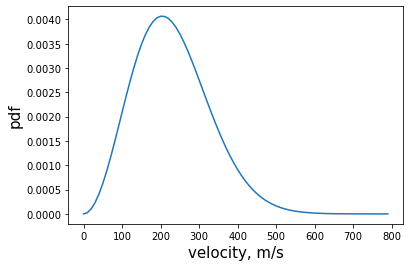

In [12]:
## maxwell boltzmann distribution ##
vList = np.arange(0, 800, 10)
vInt = np.arange(0, 600, 1)

plt.plot(vList, mB_velocity(v = vList, m = 40, T = 100))

plt.ylabel("pdf", size = 15)
plt.xlabel("velocity, m/s", size = 15)

integrate.trapz(x = vInt, y = mB_velocity(v = vInt, m = 40, T = 100))